In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=14
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 4. * nS 
g_AMPA_rec_E = 4. * nS 
g_AMPA_ext_I = 4. * nS
g_AMPA_rec_I = 4. * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 2*nS 
g_GABA_I = 2*nS 
tau_GABA = 10. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0

#HSP
tau_HSP = 1*second           
alpha_HSP = 0.001            
target_rate = 10*Hz
hsp_dt = 100*ms


tau_vm = 50*ms
vm_record_dt = 5*ms

#gif 
save_interval = 0.2*second  
frames_rec=[]
frames_inp=[]

# rf_indices = [1,25,33,46,53,64,77,85,96]
center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.4   # 40% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.2   # 20% reduction of excitatory drive onto I
ALC_INC_GABA_E = 0.5   # 50% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.3   # 30% increase of inhibitory drive onto I
ALC_Ibias_E    = -40*pA  # extra hyperpolarizing bias on E during alcohol (optional)
ALC_Ibias_I    = -10*pA  # small bias on I (optional)


kill_mask = np.ones((n_input_rows, n_input_columns), dtype=np.float32)
kill_mask[3, 3] = 0
kill_mask[3, 4] = 0
kill_mask[3, 5] = 0
kill_mask[3, 6] = 0
kill_mask[4, 3] = 0
kill_mask[4, 4] = 0
kill_mask[4, 5] = 0
kill_mask[4, 6] = 0
kill_mask[5, 3] = 0
kill_mask[5, 4] = 0
kill_mask[5, 5] = 0
kill_mask[5, 6] = 0



if alcohol:
    g_AMPA_ext_E_eff = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E)
    g_AMPA_ext_I_eff = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I)
    g_AMPA_rec_E_eff = g_AMPA_rec_E * (1 - ALC_RED_AMPA_E)
    g_AMPA_rec_I_eff = g_AMPA_rec_I * (1 - ALC_RED_AMPA_I)
    g_GABA_E_eff     = g_GABA_E     * (1 + ALC_INC_GABA_E)
    g_GABA_I_eff     = g_GABA_I     * (1 + ALC_INC_GABA_I)
    I_alc_bias_E     = ALC_Ibias_E
    I_alc_bias_I     = ALC_Ibias_I
else:
    g_AMPA_ext_E_eff = g_AMPA_ext_E
    g_AMPA_ext_I_eff = g_AMPA_ext_I
    g_AMPA_rec_E_eff = g_AMPA_rec_E
    g_AMPA_rec_I_eff = g_AMPA_rec_I
    g_GABA_E_eff     = g_GABA_E
    g_GABA_I_eff     = g_GABA_I
    I_alc_bias_E     = 0*pA
    I_alc_bias_I     = 0*pA

def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    #orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])
    orientation = 'diagonal'

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=60):
    filtered_img = abs(filtered_img)
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate
    rates = clip(rates,5,60) * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol,target_rate = 10*Hz):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_bias) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_E_eff * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E_eff * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_E_eff * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    I_bias : amp (constant)
    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz
    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    '''

    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn+ I_bias) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I_eff * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I_eff * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_I_eff * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    I_bias : amp (constant)
    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_E.I_bias = I_alc_bias_E
    P_I.I_bias = I_alc_bias_I

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(False)  

        rf_size = 3  
        half_rf = rf_size // 2


        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
                

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre='s_AMPA_ext += w', method='euler', name='PG_E')
        C_PG_E.connect(False)  
        rf_size = 3  
        half_rf = rf_size // 2
        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre='s_AMPA += w', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='s_AMPA += w', method='euler', name='E_I')
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = w_PG_E
        C_I_E.w[:] = w_I_E
        C_I_I.w[:] = w_I_I
        C_E_I.w[:] = w_E_I
        C_E_E.w[:] = w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', #model='vm_pop_post = v_pre / N_pre : volt (summed)'
                method='euler')
    C_vm.connect()
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=vm_record_dt,name='V_mon')

    # monitors
    sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    C_E_E.run_regularly('''
        delta = clip((target_rate - r_est_post)/target_rate, -1, 1);
        w = clip(w + alpha_HSP * delta, 0, w_max);
    ''', dt=hsp_dt)

    C_I_E.run_regularly('''
        delta = clip((target_rate - r_est_post)/target_rate, -1, 1);
        w = clip(w - alpha_HSP * delta, 0, w_max_i);
    ''', dt=hsp_dt)

    C_E_I.run_regularly('''
        delta = clip((target_rate - r_est_pre)/target_rate, -1, 1);
        w = clip(w - alpha_HSP * delta, 0, w_max);
    ''', dt=hsp_dt)

    C_I_I.run_regularly('''
        delta = clip((target_rate - r_est_post)/target_rate, -1, 1);
        w = clip(w - alpha_HSP * delta, 0, w_max_i);
    ''', dt=hsp_dt)    

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_img(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(1000*ms)


def show_img_mask(net, index,show_time=1000*ms):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    filtered *= kill_mask
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(show_time)


def train(N_train,alcohol,target_rate = 10*Hz):
    net = build_network(True,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_train): 
        show_img(net, index = i)
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net


def test(N_test,alcohol,show_time = 1000*ms,target_rate = 10*Hz):
    net = build_network(False,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_test):
        show_img_mask(net, index=i, show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net


def plot_eeg_like2(sp_E, V_mon, N_E,
                  window=100*ms, step=10*ms, title="EEG-like summary"):
    t_end = V_mon.t[-1]
    times = np.arange(0*ms, t_end + step, step)*second  
    active_fr = []
    for t1 in times:
        t0 = t1 - window
        if t0 < 0*ms:
            active_fr.append(np.nan)
            continue
        mask = (sp_E.t >= t0) & (sp_E.t < t1)
        if np.any(mask):
            active = np.unique(np.asarray(sp_E.i[mask]))
            active_fr.append(len(active) / float(N_E))
        else:
            active_fr.append(0.0)
    active_fr = np.array(active_fr, dtype=float)
    times_s = np.array(times/second, dtype=float)

    n=int(1000/(step/ms))
    fs = 1.0 / np.median(np.diff(times_s))  
    lowcut = 1.0   
    highcut = 30.0 
    order = 2      
    b, a = butter(order, [lowcut / (0.5 * fs), highcut / (0.5 * fs)], btype='band')
    vm_detrended = V_mon.vm_pop
    vm_detrended=np.asarray(vm_detrended, dtype=float).ravel()
    vm_filtered = filtfilt(b, a, vm_detrended)

    min_l=min(len(active_fr),len(times_s),len(vm_filtered))
    
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    axes[0].plot(times_s[n:min_l], 100.0*active_fr[n:min_l], lw=1.5)
    axes[0].set_ylabel('Active neurons (%)')
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(times_s[n:min_l], vm_filtered[n:min_l], lw=1.5)
    axes[1].set_ylabel('Mean Vm (mV)')
    axes[1].set_xlabel('Time (s)')
    axes[1].grid(True, alpha=0.3)
    axes[0].set_title(title)

    fig.tight_layout()
    plt.show()

Training (HSP+STDP)

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_02b1e1083093a997b246f1371b45f098' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_02b1e1083093a997b246f1371b45f098.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_02b1e1083093a997b246f1371b45f098.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_02b1e1083093a997b246f1371b45f098.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
0
Loading data/train_images_diag/img_001.npy (12, 12)
1
Loading data/train_images_diag/img_002.npy (12, 12)
2
Loading data/train_images_diag/img_003.npy (12, 12)
3
Loading data/train_images_diag/img_004.npy (12, 12)
4
Loading data/train_images_diag/img_005.npy (12, 12)
5
Loading data/train_images_diag/img_006.npy (12, 12)
6
Loading data/train_images_diag/img_007.npy (12, 12)
7
Loading data/train_images_diag/img_008.npy (12, 12)
8
Loading data/train_images_diag/img_009.npy (12, 12)
9
Loading data/train_images_diag/img_010.npy (12, 12)
10
Loading data/train_images_diag/img_011.npy (12, 12)
11
Loading data/train_images_diag/img_012.npy (12, 12)
12
Loading data/train_images_diag/img_013.npy (12, 12)
13
Loading data/train_images_diag/img_014.npy (12, 12)
14
Loading data/train_images_diag/img_015.npy (12, 12)
15
Loading data/train_images_diag/img_016.npy (12,

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



39
Saving (900,) data/w_PG_E.npy
Saving (1836,) data/w_E_E.npy
Saving (484,) data/w_I_E.npy
Saving (484,) data/w_E_I.npy
Saving (144,) data/w_I_I.npy


<Axes: xlabel='time (s)', ylabel='neuron index'>

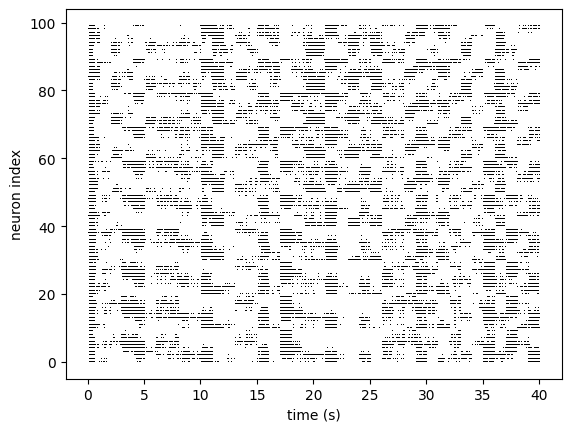

In [29]:
start_scope()
net = train(40, False) 
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')

HSP no mask

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_70ff52c56e7081375a697f357f753cc6' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_70ff52c56e7081375a697f357f753cc6.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_70ff52c56e7081375a697f357f753cc6.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_70ff52c56e7081375a697f357f753cc6.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
Tested image 1/1


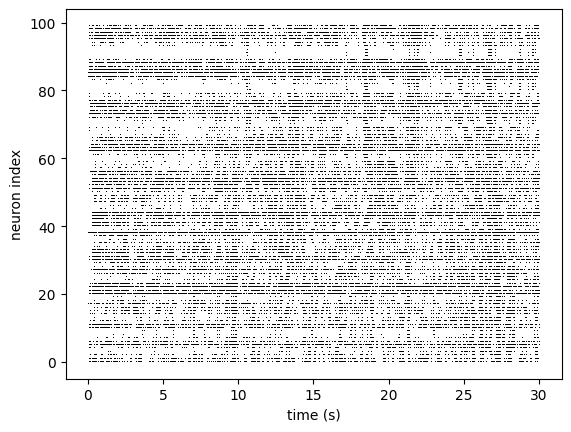

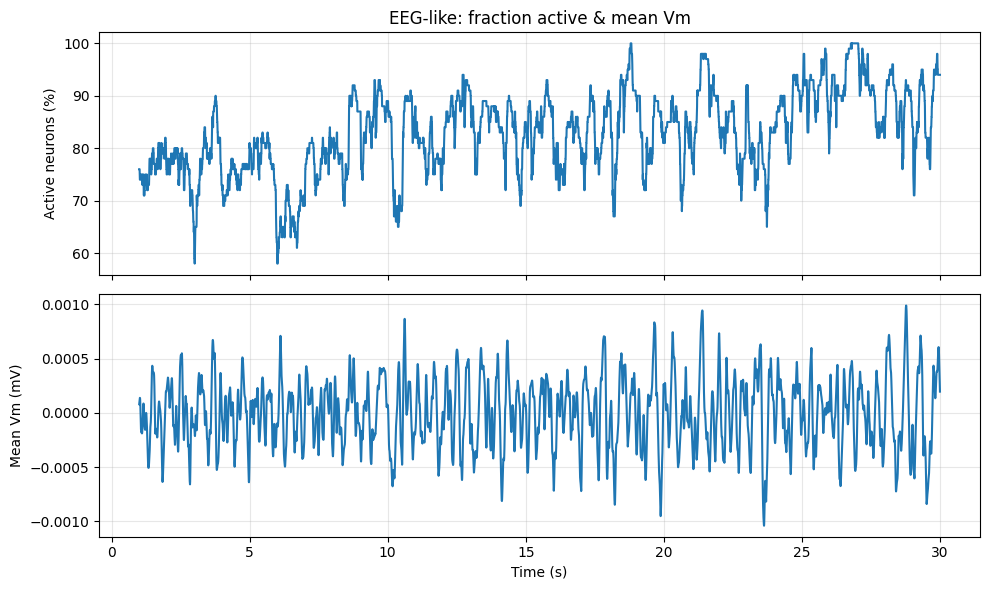

In [34]:
start_scope()
net = test(1,alcohol=False,show_time=30*second,target_rate=10*Hz)
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
V_mon = net['V_mon']  
plot_eeg_like2(exc_mon, V_mon, N_E,
              window=300*ms, step=5*ms, title="EEG-like: fraction active & mean Vm")

HSP and mask

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_2f2e6d1178d175acf62d6ec37a529c55' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_2f2e6d1178d175acf62d6ec37a529c55.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2f2e6d1178d175acf62d6ec37a529c55.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_2f2e6d1178d175acf62d6ec37a529c55.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)


WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


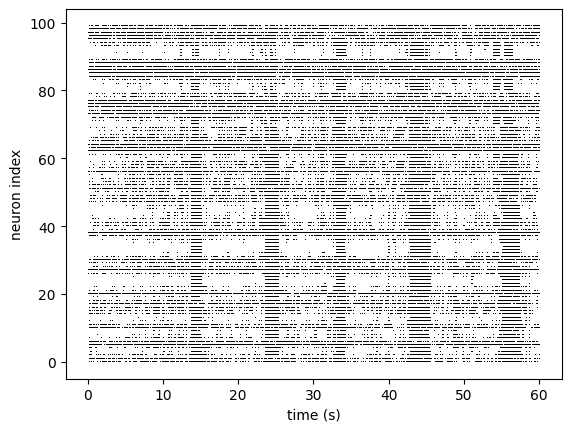

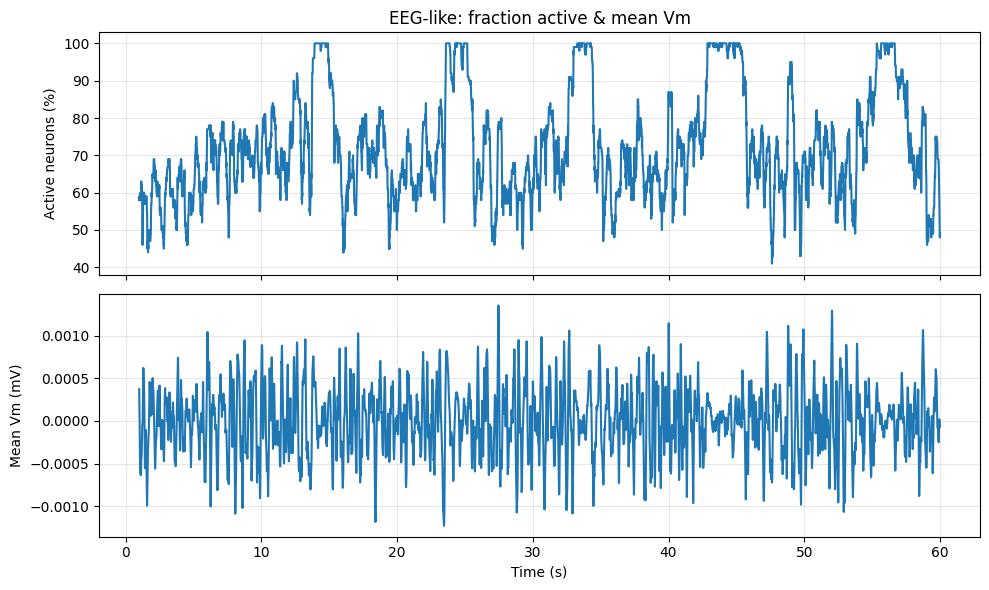

In [36]:
start_scope()
net = test(1,alcohol=False,show_time=60*second,target_rate=10*Hz)
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
V_mon = net['V_mon']  
plot_eeg_like2(exc_mon, V_mon, N_E,
              window=300*ms,   
              step=5*ms,
              title="EEG-like: fraction active & mean Vm")